## 1. Carga de los datos

En esta etapa se cargarán los conjuntos de datos preparados durante el análisis exploratorio y el preprocesamiento.

Se utilizarán los archivos intermedios almacenados en formato ZIP, que contienen las variables predictoras transformadas mediante One-Hot Encoding, la variable objetivo `bajo_peso` y los ponderadores `nacimientos_cantidad`.

Se mantendrá la división temporal definida previamente:

- **Entrenamiento:** registros correspondientes al período 2005–2018.
- **Prueba:** registros correspondientes al período 2019–2022.

El conjunto de prueba permanecerá reservado para la evaluación final del modelo.

In [1]:
import pandas as pd
import numpy as np

import zipfile

import joblib

from IPython.display import display

from itertools import product

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import set_config
import sklearn

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.metrics import f1_score, make_scorer, precision_score, recall_score, confusion_matrix, classification_report

In [2]:
ruta_datos = "../data/interim/datos_intermedios_modelado.zip"

with zipfile.ZipFile(ruta_datos, "r") as archivo:
    X_train = pd.read_csv(archivo.open("X_train.csv"))
    X_test = pd.read_csv(archivo.open("X_test.csv"))

    y_train = pd.read_csv(archivo.open("y_train.csv")).squeeze("columns")
    y_test = pd.read_csv(archivo.open("y_test.csv")).squeeze("columns")

    pesos_train = pd.read_csv(archivo.open("pesos_train.csv")).squeeze("columns")
    pesos_test = pd.read_csv(archivo.open("pesos_test.csv")).squeeze("columns")

    anio_train = pd.read_csv(archivo.open("anio_train.csv")).squeeze("columns")

    anio_test = pd.read_csv(archivo.open("anio_test.csv")).squeeze("columns")

In [3]:
ruta_preprocesador = "../data/interim/preprocesador.joblib"

preprocesador = joblib.load(ruta_preprocesador)

print("Preprocesador cargado correctamente.")

Preprocesador cargado correctamente.


In [4]:
variables_predictoras = [
    "jurisdicion_residencia_nombre",
    "edad_madre_grupo",
    "instruccion_madre",
    "tipo_de_parto_nombre",
    "semana_gestacion",
    "Sexo"
]

categorias_por_variable = preprocesador.named_transformers_[
    "categoricas"
].categories_

for variable, categorias in zip(
    variables_predictoras,
    categorias_por_variable
):
    print(f"\n{variable}:")
    print(categorias.tolist())


jurisdicion_residencia_nombre:
['Buenos Aires', 'Catamarca', 'Chaco', 'Chubut', 'Ciudad Autónoma de Buenos Aires', 'Corrientes', 'Córdoba', 'Entre Ríos', 'Formosa', 'Jujuy', 'La Pampa', 'La Rioja', 'Lugar no especificado', 'Mendoza', 'Misiones', 'Neuquén', 'Otro país', 'Río Negro', 'Salta', 'San Juan', 'San Luis', 'Santa Cruz', 'Santa Fe', 'Santiago del Estero', 'Tierra del Fuego, Antártida e Islas del Atlántico Sur', 'Tucumán']

edad_madre_grupo:
['1.Menor de 15', '2.15 a 19', '3.20 a 24', '4.25 a 29', '5.30 a 34', '6.35 a 39', '7.40 a 44', '8.De 45 y más', '9.Sin especificar']

instruccion_madre:
['1.Sin instrucción', '2.Primaria/C. EGB Incompleta', '3.Primaria/C. EGB Completa', '4.Secundaria/Polimodal Incompleta', '5.Secundaria/Polimodal Completa', '6.Terciaria/Universitaria Incompleta', '7.Terciaria/Universitaria Completa', '8.Sin especificar']

tipo_de_parto_nombre:
['Múltiple', 'Simple', 'Sin especificar']

semana_gestacion:
['1.Menos de 22', '2.22 a 23', '3.24 a 27', '4.28 a 31

In [5]:
print("Cantidad de características:", X_train.shape[1])

print("\nColumnas utilizadas por el modelo:")
print(X_train.columns.tolist())

Cantidad de características: 57

Columnas utilizadas por el modelo:
['categoricas__jurisdicion_residencia_nombre_Buenos Aires', 'categoricas__jurisdicion_residencia_nombre_Catamarca', 'categoricas__jurisdicion_residencia_nombre_Chaco', 'categoricas__jurisdicion_residencia_nombre_Chubut', 'categoricas__jurisdicion_residencia_nombre_Ciudad Autónoma de Buenos Aires', 'categoricas__jurisdicion_residencia_nombre_Corrientes', 'categoricas__jurisdicion_residencia_nombre_Córdoba', 'categoricas__jurisdicion_residencia_nombre_Entre Ríos', 'categoricas__jurisdicion_residencia_nombre_Formosa', 'categoricas__jurisdicion_residencia_nombre_Jujuy', 'categoricas__jurisdicion_residencia_nombre_La Pampa', 'categoricas__jurisdicion_residencia_nombre_La Rioja', 'categoricas__jurisdicion_residencia_nombre_Lugar no especificado', 'categoricas__jurisdicion_residencia_nombre_Mendoza', 'categoricas__jurisdicion_residencia_nombre_Misiones', 'categoricas__jurisdicion_residencia_nombre_Neuquén', 'categoricas__juri

## 2. Verificación de los datos

Antes de comenzar el entrenamiento, se verificará la estructura de los conjuntos de datos cargados.

Se comprobarán las dimensiones de las variables predictoras, la variable objetivo y los ponderadores, para asegurar que los registros estén correctamente alineados y que los conjuntos de entrenamiento y prueba mantengan la estructura esperada.

In [6]:
print("Dimensiones de los conjuntos de datos:\n")

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

print("pesos_train:", pesos_train.shape)
print("pesos_test:", pesos_test.shape)

Dimensiones de los conjuntos de datos:

X_train: (419765, 57)
X_test: (100657, 57)
y_train: (419765,)
y_test: (100657,)
pesos_train: (419765,)
pesos_test: (100657,)


## 3. Verificación de la variable objetivo

Se analizará la distribución de las clases de la variable objetivo `bajo_peso` en los conjuntos de entrenamiento y prueba.

Esta comprobación permitirá identificar el nivel de desbalance entre las categorías y verificar que ambas clases estén presentes en los dos conjuntos.

Dado que los registros representan distintas cantidades de nacimientos, también se considerarán los ponderadores `nacimientos_cantidad` para obtener la distribución correspondiente a la cantidad de nacimientos representada.

In [7]:
print("Distribución de clases en entrenamiento:")

print(
    y_train.value_counts().sort_index()
)

print("\nDistribución ponderada en entrenamiento:")

print(
    pesos_train.groupby(y_train).sum()
)

print("\nDistribución de clases en prueba:")

print(
    y_test.value_counts().sort_index()
)

print("\nDistribución ponderada en prueba:")

print(
    pesos_test.groupby(y_test).sum()
)

Distribución de clases en entrenamiento:
bajo_peso
0    242714
1    177051
Name: count, dtype: int64

Distribución ponderada en entrenamiento:
bajo_peso
0    9425543
1     736022
Name: nacimientos_cantidad, dtype: int64

Distribución de clases en prueba:
bajo_peso
0    57795
1    42862
Name: count, dtype: int64

Distribución ponderada en prueba:
bajo_peso
0    1988001
1     161894
Name: nacimientos_cantidad, dtype: int64


### Interpretación de la distribución de clases

Los resultados muestran que la clase de bajo peso no es mayoritaria en cantidad de registros, pero sí constituye una clase minoritaria cuando se considera la cantidad de nacimientos representada por cada fila.

En el conjunto de entrenamiento, los nacimientos con bajo peso representan el 7,24 % del total, mientras que en el conjunto de prueba representan el 7,53 %.

Esta diferencia se debe a que cada registro puede representar una cantidad distinta de nacimientos. Por este motivo, es necesario considerar la variable `nacimientos_cantidad` como ponderador durante el entrenamiento y la evaluación del modelo.

Para evaluar el desempeño se utilizarán métricas ponderadas, como precisión (Precision), sensibilidad (Recall) y F1-score, de manera que los resultados contemplen la cantidad de nacimientos representada por cada registro.

Por último, las proporciones ponderadas de ambos conjuntos son relativamente cercanas, lo que indica que no se observa una diferencia marcada en la distribución de la variable objetivo entre los períodos de entrenamiento y prueba.

## 4. Preparación de la validación temporal

Antes de construir las particiones de validación temporal, se comprobará que los conjuntos de características, etiquetas, ponderadores y años tengan la misma cantidad de registros.

También se verificará el orden cronológico de los años para garantizar que las particiones posteriores respeten la secuencia temporal.

In [8]:
# Verificar que todos los conjuntos tengan la misma cantidad de registros
print("Cantidad de registros:")
print("X_train:", len(X_train))
print("y_train:", len(y_train))
print("pesos_train:", len(pesos_train))
print("anio_train:", len(anio_train))

# Verificar que los índices estén alineados
print("\n¿Los índices están alineados?")
print(
    X_train.index.equals(y_train.index)
    and X_train.index.equals(pesos_train.index)
    and X_train.index.equals(anio_train.index)
)

# Verificar el orden cronológico
print("\nOrden cronológico:")
print("Años ordenados:", anio_train.is_monotonic_increasing)
print("Primer año:", anio_train.min())
print("Último año:", anio_train.max())

# Cantidad de registros por año
print("\nRegistros por año:")
display(anio_train.value_counts().sort_index())

Cantidad de registros:
X_train: 419765
y_train: 419765
pesos_train: 419765
anio_train: 419765

¿Los índices están alineados?
True

Orden cronológico:
Años ordenados: True
Primer año: 2005
Último año: 2018

Registros por año:


anio
2005    30743
2006    29965
2007    30005
2008    30996
2009    30725
2010    30878
2011    29688
2012    29607
2013    29399
2014    30276
2015    29306
2016    29283
2017    29938
2018    28956
Name: count, dtype: int64

### 4.1. Ordenamiento cronológico

Se ordenarán los registros del conjunto de entrenamiento según el año correspondiente. Se aplicará la misma reorganización a las características, las etiquetas y los ponderadores para conservar la correspondencia entre los datos.

In [9]:
# Obtener el orden cronológico de los registros
orden_train = anio_train.sort_values(kind="stable").index

# Aplicar el mismo orden a todos los conjuntos
X_train = X_train.loc[orden_train].reset_index(drop=True)
y_train = y_train.loc[orden_train].reset_index(drop=True)
pesos_train = pesos_train.loc[orden_train].reset_index(drop=True)
anio_train = anio_train.loc[orden_train].reset_index(drop=True)

print("¿Los años quedaron ordenados?")
print(anio_train.is_monotonic_increasing)

print("\n¿Los índices siguen alineados?")
print(
    X_train.index.equals(y_train.index)
    and X_train.index.equals(pesos_train.index)
    and X_train.index.equals(anio_train.index)
)

print("\nPrimeros y últimos años:")
print(anio_train.min(), "-", anio_train.max())

¿Los años quedaron ordenados?
True

¿Los índices siguen alineados?
True

Primeros y últimos años:
2005 - 2018


### 4.2. Construcción de las particiones temporales

Se definirán cuatro particiones de validación temporal utilizando años completos. En cada partición, el modelo se entrenará con los registros de los años anteriores y se validará con los dos años siguientes.

Esta estrategia permite respetar el orden cronológico y evita que registros de un mismo año queden distribuidos entre entrenamiento y validación.

In [10]:
periodos_cv = [
    (2010, 2012),
    (2012, 2014),
    (2014, 2016),
    (2016, 2018)
]

particiones_temporales = []

for anio_inicio, anio_fin in periodos_cv:

    indices_entrenamiento = np.flatnonzero(
        (anio_train <= anio_inicio).to_numpy()
    )

    indices_validacion = np.flatnonzero(
        (
            (anio_train > anio_inicio) &
            (anio_train <= anio_fin)
        ).to_numpy()
    )

    particiones_temporales.append(
        (indices_entrenamiento, indices_validacion)
    )

print("Cantidad de particiones:", len(particiones_temporales))

Cantidad de particiones: 4


### 4.3. Verificación de las particiones temporales

Se comprobará que cada partición respete la secuencia temporal establecida, utilizando años completos para los conjuntos de entrenamiento y validación. También se verificará la cantidad de registros y de nacimientos representados en cada período.

In [11]:
for numero, (indices_train, indices_val) in enumerate(
    particiones_temporales, start=1
):
    anios_entrenamiento = anio_train.iloc[indices_train]
    anios_validacion = anio_train.iloc[indices_val]

    print(f"Partición {numero}")
    print(
        f"Entrenamiento: {anios_entrenamiento.min()}–"
        f"{anios_entrenamiento.max()}"
    )
    print(
        f"Validación: {anios_validacion.min()}–"
        f"{anios_validacion.max()}"
    )
    print(f"Registros de entrenamiento: {len(indices_train):,}")
    print(f"Registros de validación: {len(indices_val):,}")
    print(
        "Nacimientos en entrenamiento: "
        f"{pesos_train.iloc[indices_train].sum():,.0f}"
    )
    print(
        "Nacimientos en validación: "
        f"{pesos_train.iloc[indices_val].sum():,.0f}"
    )
    print()

Partición 1
Entrenamiento: 2005–2010
Validación: 2011–2012
Registros de entrenamiento: 183,312
Registros de validación: 59,295
Nacimientos en entrenamiento: 4,308,372
Nacimientos en validación: 1,478,697

Partición 2
Entrenamiento: 2005–2012
Validación: 2013–2014
Registros de entrenamiento: 242,607
Registros de validación: 59,675
Nacimientos en entrenamiento: 5,787,069
Nacimientos en validación: 1,516,843

Partición 3
Entrenamiento: 2005–2014
Validación: 2015–2016
Registros de entrenamiento: 302,282
Registros de validación: 58,589
Nacimientos en entrenamiento: 7,303,912
Nacimientos en validación: 1,480,361

Partición 4
Entrenamiento: 2005–2016
Validación: 2017–2018
Registros de entrenamiento: 360,871
Registros de validación: 58,894
Nacimientos en entrenamiento: 8,784,273
Nacimientos en validación: 1,377,292



## 5. Comparación del balanceo de clases

Para realizar la clasificación retrospectiva se utilizará el algoritmo Random Forest. Este método combina múltiples árboles de decisión y permite abordar problemas de clasificación mediante la integración de sus predicciones.

Se establecerán algunos parámetros generales del modelo, mientras que otros serán evaluados posteriormente mediante una búsqueda de hiperparámetros utilizando las particiones de validación temporal.

In [12]:
modelo_rf = RandomForestClassifier(
    n_estimators=300,
    random_state=42,
    n_jobs=1
)

### 5.1 Evaluación de las estrategias de balanceo

Antes de realizar la búsqueda de hiperparámetros, se compararán dos configuraciones del algoritmo Random Forest: una sin ponderación adicional de clases (`class_weight=None`) y otra con balanceo automático (`class_weight="balanced"`).

La comparación se realizará mediante las cuatro particiones temporales definidas anteriormente, utilizando exclusivamente los datos de entrenamiento (2005–2018).

Se empleará `nacimientos_cantidad` como ponderación tanto durante el entrenamiento como en la evaluación. De esta manera, las métricas representarán el desempeño considerando la cantidad de nacimientos agrupados en cada registro.

Se analizarán la precisión (Precision), la sensibilidad (Recall) y la medida F1 (F1-score), utilizando esta última como criterio principal de comparación.

In [13]:
set_config(enable_metadata_routing=True)

modelo_rf.set_fit_request(sample_weight=True)

scoring_balanceo = {
    "precision": make_scorer(precision_score, zero_division=0),
    "recall": make_scorer(recall_score, zero_division=0),
    "f1": make_scorer(f1_score, zero_division=0)
}

for scorer in scoring_balanceo.values():
    scorer.set_score_request(sample_weight=True)

busqueda_balanceo = GridSearchCV(
    estimator=modelo_rf,
    param_grid={
        "class_weight": [None, "balanced"]
    },
    scoring=scoring_balanceo,
    cv=particiones_temporales,
    refit=False,
    n_jobs=1,
    return_train_score=False
)

busqueda_balanceo.fit(
    X_train,
    y_train,
    sample_weight=pesos_train
)

,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'class_weight': [None, 'balanced']}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","{'f1': make_scorer(f...ro_division=0), 'precision': make_scorer(p...ro_division=0), 'recall': make_scorer(r...ro_division=0)}"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",False
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None change

### 5.2 Análisis de los resultados de la comparación

Una vez finalizada la validación temporal, se organizarán los resultados obtenidos para cada estrategia de balanceo.

Se presentarán las métricas promedio de Precision, Recall y F1-score, junto con la variabilidad del F1-score entre las cuatro particiones temporales.

Esta comparación permitirá analizar las diferencias entre ambas configuraciones y seleccionar la estrategia que presente el mejor desempeño promedio según la medida F1.

In [14]:
resultados_balanceo = pd.DataFrame(
    busqueda_balanceo.cv_results_
)

columnas_resultados = [
    "param_class_weight",
    "mean_test_precision",
    "mean_test_recall",
    "mean_test_f1",
    "std_test_f1",
    "split0_test_f1",
    "split1_test_f1",
    "split2_test_f1",
    "split3_test_f1"
]

df_resultados_balanceo = resultados_balanceo[
    columnas_resultados
].copy()

df_resultados_balanceo = df_resultados_balanceo.rename(
    columns={
        "param_class_weight": "Balanceo",
        "mean_test_precision": "Precision promedio",
        "mean_test_recall": "Recall promedio",
        "mean_test_f1": "F1 promedio",
        "std_test_f1": "Desviación estándar F1",
        "split0_test_f1": "F1 período 1",
        "split1_test_f1": "F1 período 2",
        "split2_test_f1": "F1 período 3",
        "split3_test_f1": "F1 período 4"
    }
)

display(df_resultados_balanceo)

,Balanceo,Precision promedio,Recall promedio,F1 promedio,Desviación estándar F1,F1 período 1,F1 período 2,F1 período 3,F1 período 4
0,NaN,0.720980,0.331255,0.453826,0.006733,0.459853,0.449875,0.460765,0.444812
1,balanced,0.491647,0.684988,0.572416,0.005477,0.564194,0.572461,0.579584,0.573424


### 5.3 Selección de la estrategia de balanceo

La estrategia de balanceo se seleccionará considerando el F1-score promedio obtenido durante la validación temporal. Esta métrica permite evaluar conjuntamente la precisión y la sensibilidad del modelo.

También se tendrán en cuenta Precision y Recall para interpretar las diferencias entre ambas configuraciones, así como la variabilidad del F1-score entre los períodos evaluados.

La estrategia seleccionada se utilizará posteriormente durante la búsqueda de hiperparámetros, manteniendo el conjunto de prueba de 2019–2022 reservado para la evaluación final.

In [15]:
mejor_balanceo = df_resultados_balanceo.loc[
    df_resultados_balanceo["F1 promedio"].idxmax(),
    "Balanceo"
]

print("Estrategia de balanceo seleccionada:", mejor_balanceo)

Estrategia de balanceo seleccionada: balanced


## 6. Búsqueda de hiperparámetros

Una vez seleccionada la estrategia de balanceo de clases, se realizará una búsqueda de hiperparámetros mediante `GridSearchCV`.

Se evaluarán distintas combinaciones de parámetros del algoritmo Random Forest utilizando las mismas cuatro particiones temporales definidas previamente.

La búsqueda se realizará exclusivamente sobre los datos de entrenamiento correspondientes al período 2005–2018. El F1-score ponderado por la cantidad de nacimientos se utilizará como criterio principal para seleccionar la mejor configuración.

Para reducir el costo computacional, se utilizará una grilla de 16 combinaciones, manteniendo 300 árboles por modelo.

### 6.1 Definición de la grilla de hiperparámetros

Se evaluarán combinaciones de profundidad máxima, cantidad mínima de muestras para dividir un nodo, cantidad mínima de muestras por hoja y número de características consideradas en cada división.

In [16]:
grilla_hiperparametros = {
    "max_depth": [None, 20],
    "min_samples_split": [2, 10],
    "min_samples_leaf": [1, 5],
    "max_features": ["sqrt", 0.5]
}

print(
    "Cantidad de combinaciones:",
    np.prod([
        len(valores)
        for valores in grilla_hiperparametros.values()
    ])
)

Cantidad de combinaciones: 16


### 6.2 Configuración de la búsqueda

Se configurará `GridSearchCV` para evaluar las 16 combinaciones de hiperparámetros mediante las cuatro particiones temporales.

Se mantendrá la estrategia de balanceo seleccionada en la etapa anterior. La búsqueda utilizará el F1-score ponderado por la cantidad de nacimientos como criterio principal de selección.

La opción `refit=False` evitará un entrenamiento adicional automático al finalizar la búsqueda, ya que el modelo definitivo se entrenará posteriormente con todos los datos de entrenamiento.

In [17]:
modelo_busqueda = RandomForestClassifier(
    n_estimators=300,
    class_weight=mejor_balanceo,
    random_state=42,
    n_jobs=1
)

modelo_busqueda.set_fit_request(sample_weight=True)

scorer_f1 = make_scorer(
    f1_score,
    zero_division=0
)

scorer_f1.set_score_request(sample_weight=True)

busqueda_hiperparametros = GridSearchCV(
    estimator=modelo_busqueda,
    param_grid=grilla_hiperparametros,
    scoring=scorer_f1,
    cv=particiones_temporales,
    refit=False,
    n_jobs=1,
    return_train_score=False
)

### 6.3 Ejecución de la búsqueda

Se ejecutará la búsqueda de hiperparámetros utilizando los datos de entrenamiento y sus correspondientes ponderaciones.

Cada combinación será evaluada mediante las cuatro particiones temporales. El conjunto de prueba de 2019–2022 permanecerá excluido de este procedimiento.

La búsqueda permitirá identificar la configuración con el mayor F1-score promedio ponderado por la cantidad de nacimientos.

In [18]:
busqueda_hiperparametros.fit(
    X_train,
    y_train,
    sample_weight=pesos_train
)

print("Búsqueda de hiperparámetros finalizada.")
print(
    "Cantidad de combinaciones evaluadas:",
    len(busqueda_hiperparametros.cv_results_["params"])
)
print("Cantidad total de entrenamientos:", 64)

Búsqueda de hiperparámetros finalizada.
Cantidad de combinaciones evaluadas: 16
Cantidad total de entrenamientos: 64


### 6.4 Análisis de los resultados de la búsqueda

Los resultados de la búsqueda se organizarán según el F1-score promedio obtenido en las cuatro particiones temporales.

Se presentarán las combinaciones de hiperparámetros evaluadas, junto con su desempeño promedio y la desviación estándar del F1-score.

Esta información permitirá identificar las configuraciones con mejor desempeño y observar la variabilidad de sus resultados entre los distintos períodos de validación.

In [19]:
resultados_busqueda = pd.DataFrame(
    busqueda_hiperparametros.cv_results_
)

columnas_resultados = [
    "params",
    "mean_test_score",
    "std_test_score",
    "split0_test_score",
    "split1_test_score",
    "split2_test_score",
    "split3_test_score"
]

df_resultados_busqueda = (
    resultados_busqueda[columnas_resultados]
    .copy()
    .sort_values(
        by="mean_test_score",
        ascending=False
    )
    .reset_index(drop=True)
)

df_resultados_busqueda = df_resultados_busqueda.rename(
    columns={
        "params": "Hiperparámetros",
        "mean_test_score": "F1 promedio",
        "std_test_score": "Desviación estándar F1",
        "split0_test_score": "F1 período 1",
        "split1_test_score": "F1 período 2",
        "split2_test_score": "F1 período 3",
        "split3_test_score": "F1 período 4"
    }
)

display(df_resultados_busqueda)

,Hiperparámetros,F1 promedio,Desviación estándar F1,F1 período 1,F1 período 2,F1 período 3,F1 período 4
0,"{'max_depth': 20, 'max_features': 0.5, 'min_sa...",0.574440,0.004686,0.567735,0.574266,0.580978,0.574781
1,"{'max_depth': 20, 'max_features': 0.5, 'min_sa...",0.574410,0.004694,0.567902,0.574411,0.581172,0.574155
2,"{'max_depth': 20, 'max_features': 0.5, 'min_sa...",0.574321,0.004627,0.567718,0.574329,0.580804,0.574432
3,"{'max_depth': 20, 'max_features': 0.5, 'min_sa...",0.574321,0.004627,0.567718,0.574329,0.580804,0.574432
4,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.573999,0.005042,0.566565,0.574368,0.580797,0.574266
5,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.573999,0.005042,0.566565,0.574368,0.580797,0.574266
6,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.573399,0.004991,0.566067,0.574032,0.580143,0.573356
7,"{'max_depth': None, 'max_features': 'sqrt', 'm...",0.573227,0.005149,0.565655,0.573644,0.580191,0.573419
8,"{'max_depth': 20, 'max_features': 'sqrt', 'min...",0.573107,0.005121,0.565808,0.574004,0.580201,0.572414
9,"{'max_depth': None, 'max_features': 0.5, 'min_...",0.573097,0.005292,0.565252,0.573075,0.580158,0.573904


### 6.5 Selección de la mejor configuración

Se seleccionará la combinación de hiperparámetros que haya obtenido el mayor F1-score promedio durante la validación temporal.

La configuración seleccionada se utilizará para entrenar el modelo definitivo con la totalidad de los datos de entrenamiento correspondientes al período 2005–2018.

In [20]:
indice_mejor = np.argmax(
    busqueda_hiperparametros.cv_results_["mean_test_score"]
)

mejores_parametros = (
    busqueda_hiperparametros.cv_results_["params"][indice_mejor]
)

mejor_f1 = (
    busqueda_hiperparametros.cv_results_["mean_test_score"][indice_mejor]
)

print("Mejores hiperparámetros:")
print(mejores_parametros)

print("\nMejor F1-score promedio:")
print(round(mejor_f1, 4))

Mejores hiperparámetros:
{'max_depth': 20, 'max_features': 0.5, 'min_samples_leaf': 1, 'min_samples_split': 2}

Mejor F1-score promedio:
0.5744


### 6.6 Entrenamiento del modelo definitivo

Una vez seleccionados los hiperparámetros y la estrategia de balanceo, se entrenará el modelo Random Forest definitivo utilizando la totalidad de los datos de entrenamiento correspondientes al período 2005–2018.

El entrenamiento incorporará la ponderación por cantidad de nacimientos mediante `sample_weight`, manteniendo la configuración de balanceo seleccionada durante la etapa de validación.

Este modelo será utilizado posteriormente para generar predicciones sobre los registros correspondientes al período 2019–2022.

In [21]:
modelo_definitivo = RandomForestClassifier(
    n_estimators=300,
    class_weight=mejor_balanceo,
    random_state=42,
    n_jobs=-1,
    **mejores_parametros
)

modelo_definitivo.fit(
    X_train,
    y_train,
    sample_weight=pesos_train
)

print("Entrenamiento del modelo definitivo finalizado.")

Entrenamiento del modelo definitivo finalizado.


### 6.7 Generación de predicciones

Una vez entrenado el modelo definitivo, se generarán predicciones sobre el conjunto de prueba correspondiente a los años 2019–2022.

Estos datos no participaron en la selección de la estrategia de balanceo ni en la búsqueda de hiperparámetros. Por lo tanto, permitirán evaluar el desempeño del modelo sobre registros de un período posterior al utilizado durante el entrenamiento.

In [22]:
predicciones_test = modelo_definitivo.predict(X_test)

print("Cantidad de predicciones:", len(predicciones_test))
print("Predicciones generadas correctamente.")

Cantidad de predicciones: 100657
Predicciones generadas correctamente.


### 6.8 Evaluación del modelo

El desempeño del modelo se evaluará comparando las predicciones con las categorías reales del conjunto de prueba.

Se calcularán Precision, Recall y F1-score, utilizando `nacimientos_cantidad` como ponderación para que las métricas representen la cantidad de nacimientos de cada registro.

Estas métricas permitirán analizar la capacidad del modelo para identificar los registros correspondientes a cada categoría, considerando el desempeño sobre el período 2019–2022.

In [23]:
print(
    classification_report(
        y_test,
        predicciones_test,
        sample_weight=pesos_test,
        target_names=["Sin bajo peso", "Bajo peso"],
        zero_division=0
    )
)

               precision    recall  f1-score   support

Sin bajo peso       0.97      0.95      0.96 1988001.0
    Bajo peso       0.52      0.70      0.59  161894.0

     accuracy                           0.93 2149895.0
    macro avg       0.75      0.82      0.78 2149895.0
 weighted avg       0.94      0.93      0.93 2149895.0



### 6.9 Matriz de confusión

Se construirá una matriz de confusión ponderada por la cantidad de nacimientos para comparar las categorías reales con las predichas por el modelo.

Esta representación permitirá identificar los nacimientos correctamente clasificados y aquellos que fueron asignados a una categoría incorrecta.

Se prestará especial atención a los falsos negativos de la categoría `Bajo peso`, es decir, los nacimientos con bajo peso que fueron clasificados como `Sin bajo peso`.

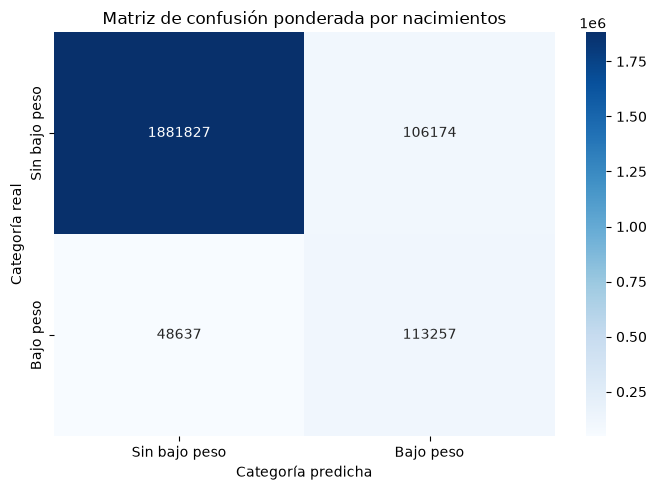

In [26]:
matriz_confusion = confusion_matrix(
    y_test,
    predicciones_test,
    sample_weight=pesos_test
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    matriz_confusion,
    annot=True,
    fmt=".0f",
    cmap="Blues",
    xticklabels=["Sin bajo peso", "Bajo peso"],
    yticklabels=["Sin bajo peso", "Bajo peso"]
)

plt.xlabel("Categoría predicha")
plt.ylabel("Categoría real")
plt.title("Matriz de confusión ponderada por nacimientos")

plt.tight_layout()
plt.show()

### 6.10 Evaluación del desempeño por año

Se analizará el desempeño del modelo de manera independiente para cada año del período de prueba (2019–2022).

Para cada año se calcularán Precision, Recall y F1-score, utilizando la cantidad de nacimientos como ponderación.

Este análisis permitirá observar si el desempeño del modelo se mantiene relativamente estable o presenta variaciones entre los distintos años. También permitirá identificar posibles diferencias en su capacidad de clasificación a lo largo del período evaluado.

In [27]:
resultados_por_anio = []

for anio in sorted(anio_test.unique()):

    mascara_anio = anio_test == anio

    y_real_anio = y_test.loc[mascara_anio]
    predicciones_anio = predicciones_test[mascara_anio]
    pesos_anio = pesos_test.loc[mascara_anio]

    resultados_por_anio.append({
        "Año": anio,
        "Nacimientos": pesos_anio.sum(),
        "Precision": precision_score(
            y_real_anio,
            predicciones_anio,
            sample_weight=pesos_anio,
            zero_division=0
        ),
        "Recall": recall_score(
            y_real_anio,
            predicciones_anio,
            sample_weight=pesos_anio,
            zero_division=0
        ),
        "F1-score": f1_score(
            y_real_anio,
            predicciones_anio,
            sample_weight=pesos_anio,
            zero_division=0
        )
    })

df_resultados_anuales = pd.DataFrame(resultados_por_anio)

display(
    df_resultados_anuales.round(4)
)

,Año,Nacimientos,Precision,Recall,F1-score
0,2019,620606,0.5019,0.6978,0.5839
1,2020,521370,0.5089,0.6992,0.5891
2,2021,517092,0.5214,0.7042,0.5992
3,2022,490827,0.5368,0.6975,0.6067


## 7. Prueba demostrativa con datos sintéticos

Con el propósito de demostrar el funcionamiento del modelo entrenado ante nuevos registros, se realizará una prueba utilizando datos sintéticos.

Se construirán registros ficticios con características compatibles con las variables predictoras utilizadas durante el entrenamiento. Posteriormente, el modelo generará una clasificación para cada uno de ellos según la condición de bajo peso al nacer.

Esta prueba tendrá un carácter exclusivamente demostrativo. Las predicciones obtenidas no representan nacimientos reales ni permiten evaluar el desempeño o la capacidad de generalización del modelo, aspectos que fueron analizados previamente mediante el conjunto de prueba correspondiente a 2019–2022.

Los datos sintéticos no incluirán la variable objetivo ni información derivada del peso al nacer como entrada del modelo.

### 7.1. Construcción de registros sintéticos

Se construirán tres registros ficticios utilizando las seis variables predictoras originales. Los valores seleccionados corresponden a categorías reconocidas durante el entrenamiento del preprocesador.

Los registros no representan personas ni nacimientos reales. Su finalidad es demostrar el flujo de transformación y clasificación de nuevos datos.

In [28]:
datos_sinteticos = pd.DataFrame([
    {
        "jurisdicion_residencia_nombre": "Buenos Aires",
        "edad_madre_grupo": "3.20 a 24",
        "instruccion_madre": "5.Secundaria/Polimodal Completa",
        "tipo_de_parto_nombre": "Simple",
        "semana_gestacion": "6.37 a 41",
        "Sexo": "Mujer"
    },
    {
        "jurisdicion_residencia_nombre": "Córdoba",
        "edad_madre_grupo": "7.40 a 44",
        "instruccion_madre": "7.Terciaria/Universitaria Completa",
        "tipo_de_parto_nombre": "Múltiple",
        "semana_gestacion": "5.32 a 36",
        "Sexo": "Varón"
    },
    {
        "jurisdicion_residencia_nombre": "Tucumán",
        "edad_madre_grupo": "2.15 a 19",
        "instruccion_madre": "2.Primaria/C. EGB Incompleta",
        "tipo_de_parto_nombre": "Simple",
        "semana_gestacion": "7.42 y más",
        "Sexo": "Mujer"
    }
])

display(datos_sinteticos)

,jurisdicion_residencia_nombre,edad_madre_grupo,instruccion_madre,tipo_de_parto_nombre,semana_gestacion,Sexo
0,Buenos Aires,3.20 a 24,5.Secundaria/Polimodal Completa,Simple,6.37 a 41,Mujer
1,Córdoba,7.40 a 44,7.Terciaria/Universitaria Completa,Múltiple,5.32 a 36,Varón
2,Tucumán,2.15 a 19,2.Primaria/C. EGB Incompleta,Simple,7.42 y más,Mujer


### 7.2. Transformación de los registros sintéticos

Se aplica el preprocesador previamente ajustado durante el entrenamiento para transformar los registros sintéticos mediante One-Hot Encoding.

De esta manera, las seis variables categóricas originales se convierten en las 57 características binarias utilizadas por el modelo, conservando las mismas categorías y estructura del conjunto de entrenamiento.

In [29]:
X_sinteticos_encoded = preprocesador.transform(
    datos_sinteticos
)

if hasattr(X_sinteticos_encoded, "toarray"):
    X_sinteticos_encoded = X_sinteticos_encoded.toarray()

X_sinteticos_encoded = pd.DataFrame(
    X_sinteticos_encoded,
    columns=preprocesador.get_feature_names_out()
)

print("Dimensiones de los datos transformados:")
print(X_sinteticos_encoded.shape)

print("\n¿Coinciden las columnas con las del entrenamiento?")
print(X_sinteticos_encoded.columns.equals(X_train.columns))

Dimensiones de los datos transformados:
(3, 57)

¿Coinciden las columnas con las del entrenamiento?
True


### 7.3. Predicción sobre los registros sintéticos

Se utiliza el modelo Random Forest definitivo, previamente entrenado, para generar predicciones sobre los registros sintéticos transformados.

Las predicciones permitirán observar la clasificación asignada a cada registro según las categorías de bajo peso y sin bajo peso.

Esta demostración no constituye una evaluación del desempeño del modelo ni permite extraer conclusiones sobre nacimientos reales.

In [30]:
predicciones_sinteticas = modelo_definitivo.predict(
    X_sinteticos_encoded
)

resultados_sinteticos = datos_sinteticos.copy()

resultados_sinteticos["Clasificación predicha"] = (
    pd.Series(predicciones_sinteticas)
    .map({
        0: "Sin bajo peso",
        1: "Bajo peso"
    })
)

display(resultados_sinteticos)

,jurisdicion_residencia_nombre,edad_madre_grupo,instruccion_madre,tipo_de_parto_nombre,semana_gestacion,Sexo,Clasificación predicha
0,Buenos Aires,3.20 a 24,5.Secundaria/Polimodal Completa,Simple,6.37 a 41,Mujer,Sin bajo peso
1,Córdoba,7.40 a 44,7.Terciaria/Universitaria Completa,Múltiple,5.32 a 36,Varón,Bajo peso
2,Tucumán,2.15 a 19,2.Primaria/C. EGB Incompleta,Simple,7.42 y más,Mujer,Sin bajo peso


## 8. Conclusiones generales

En este notebook se desarrolló y evaluó un modelo de clasificación basado en Random Forest, con el objetivo de clasificar retrospectivamente registros de nacimientos según la condición de bajo peso al nacer. Para ello, se utilizaron características maternas y del nacimiento, manteniendo la cantidad de nacimientos representada por cada registro como ponderación durante el entrenamiento y la evaluación.

En primer lugar, se compararon dos estrategias de balanceo de clases: sin ponderación adicional (`class_weight=None`) y con ponderación automática (`class_weight="balanced"`). La segunda obtuvo mejores resultados durante la validación temporal, alcanzando un F1-score promedio de 0,5724 frente a 0,4538 de la configuración sin balanceo. Por este motivo, se seleccionó `class_weight="balanced"` para las etapas posteriores.

Posteriormente, se realizó una búsqueda de hiperparámetros mediante validación temporal sobre los datos correspondientes al período 2005–2018. La mejor configuración obtenida fue `max_depth=20`, `max_features=0.5`, `min_samples_leaf=1` y `min_samples_split=2`, con un F1-score promedio de 0,5744. Las diferencias entre las mejores combinaciones fueron reducidas, por lo que la configuración seleccionada representa la mejor alternativa dentro de las evaluadas, sin que esto implique una superioridad considerable respecto de las demás.

La evaluación final se realizó sobre los registros correspondientes al período 2019–2022, que se mantuvo separado durante el entrenamiento y la selección de hiperparámetros. Para la clase **Bajo peso**, el modelo obtuvo una Precision de 0,52, un Recall de 0,70 y un F1-score de 0,59. Esto indica que logró identificar aproximadamente el 70 % de los nacimientos que realmente presentaban bajo peso, aunque también clasificó erróneamente como positivos una cantidad considerable de nacimientos que no pertenecían a esa categoría. En términos ponderados por nacimientos, identificó correctamente 113.257 casos de bajo peso y no logró identificar otros 48.637.

La elección del F1-score como métrica principal de evaluación responde al carácter retrospectivo del proyecto. Dado que se realiza una clasificación de registros históricos para analizar el comportamiento del modelo, sin que sus predicciones estén asociadas a decisiones clínicas o intervenciones concretas, no se ha definido un costo diferencial entre los falsos positivos y los falsos negativos. Por este motivo, se adoptó un criterio prudente, buscando un equilibrio entre Precision y Recall, en lugar de priorizar exclusivamente una de estas métricas.

Al analizar el comportamiento por año, se observó que el F1-score de la clase Bajo peso aumentó progresivamente, desde 0,5839 en 2019 hasta 0,6067 en 2022. Esta evolución estuvo acompañada por una mejora de Precision, mientras que Recall se mantuvo relativamente estable, en torno al 70 %. Estos resultados muestran que el modelo conservó un comportamiento relativamente consistente durante el período evaluado, aunque no permiten atribuir las variaciones observadas a una causa específica.

Finalmente, se realizó una prueba demostrativa utilizando tres registros sintéticos. Estos fueron procesados mediante el preprocesador previamente entrenado y posteriormente clasificados por el modelo definitivo. La prueba permitió comprobar que el flujo de transformación y clasificación puede aplicarse a nuevos registros con la misma estructura de variables, aunque, por tratarse de ejemplos ficticios, sus resultados no constituyen una evaluación adicional del rendimiento del modelo.

En conjunto, los resultados muestran que Random Forest logró reconocer patrones presentes en los registros históricos y mantener un desempeño relativamente estable al evaluar períodos posteriores al entrenamiento. Sin embargo, la capacidad de clasificación de la categoría Bajo peso todavía presenta limitaciones, especialmente por la cantidad de falsos positivos y falsos negativos.

Por último, debe considerarse que el estudio utiliza registros agregados y que la semana de gestación corresponde a información registrada al momento del nacimiento. Por lo tanto, el modelo no constituye una herramienta de predicción prenatal ni permite establecer relaciones causales entre las variables analizadas y la condición de bajo peso. Su alcance se limita a la clasificación retrospectiva de los registros disponibles y al análisis del comportamiento del modelo sobre períodos posteriores.